# M5: High-Resolution Skip-Enhanced Siamese U-Net

This notebook trains and evaluates M5 on the LEVIR-CD subset used in the project. M5 is based on the 256 × 256 version of M2. It keeps the shared ResNet50 encoder and the four-scale temporal fusion pathway, and adds a small branch that extracts features directly from the two input images at full resolution.

The additional branch applies the same shallow CNN to the before and after images. Its two feature maps and their absolute difference are combined, projected to 16 channels, and joined to the decoder at 256 × 256. A final convolution refines the combined features before the model produces the change-probability mask.

The branch is intended to retain local spatial information that may be reduced by the encoder's downsampling. Whether this addition improves the predictions is assessed using the validation and test results below; an improvement is not assumed in advance.

The run uses seed 44, a batch size of 2 and mixed-precision computation when a GPU is available. The notebook was run in Google Colab with an NVIDIA T4. If memory is insufficient, reduce the batch size before rerunning the data pipeline and model construction.


## M5 architecture

The main pathway follows M2-256. A shared ResNet50 extracts features from the two dates, and the temporal fusion operation at each selected scale combines the two feature maps with their absolute difference.

M5 adds a separate shallow pathway. The same small CNN is applied to both preprocessed inputs:

\[
S_A = g(I_A), \qquad S_B = g(I_B)
\]

The shallow features are fused as follows:

\[
S = Conv_{1\times1}\bigl(Concat(S_A,S_B,|S_A-S_B|)\bigr)
\]

The resulting 16-channel feature map is concatenated with the main decoder output at 256 × 256. A 3 × 3 convolution refines the combined features before the final 1 × 1 sigmoid layer produces the change-probability mask.

The shallow CNN contains a 3 × 3 convolution with 16 channels, batch normalization and ReLU, followed by a 16-channel separable convolution, batch normalization and ReLU. Its weights are shared between the two dates. Apart from this branch and the final decoder refinement, the encoder, temporal fusion projections and decoder follow M2-256.


## 1. Connect Google Drive and locate the dataset

Mount Google Drive and set `DATASET_ROOT` to the folder that contains the `train`, `val` and `test` directories. Each split is expected to contain three folders: `A`, `B` and `label`.

The path in the code is the location used for this run. Change it only if the dataset is stored elsewhere. If the validation folder is named `valid`, update the value of `SPLITS["val"]` to match.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# EDIT THIS to the directory containing train/, val/, and test/
DATASET_ROOT = "/content/drive/MyDrive/LEVIR-CD/LEVIR CD"

# Expected subfolder names
SPLITS = {
    "train": "train",
    "val": "val",
    "test": "test",
}

# Original source images are 1024x1024; resize each complete image to 256x256.
IMG_SIZE = 256
BATCH_SIZE = 2  # T4-safe starting point; reduce to 1 if GPU OOM occurs.
SEED = 44

import os
os.makedirs("/content/m5_checkpoints_256", exist_ok=True)

for split_name, folder in SPLITS.items():
    split_path = os.path.join(DATASET_ROOT, folder)
    assert os.path.isdir(split_path), f"Missing split folder: {split_path}"

print("Dataset root:", DATASET_ROOT)
print("M5 image size:", IMG_SIZE)
print("M5 batch size:", BATCH_SIZE)
print("GPU devices:", __import__("tensorflow").config.list_physical_devices("GPU"))


Mounted at /content/drive
Dataset root: /content/drive/MyDrive/LEVIR-CD/LEVIR CD
M5 image size: 256
M5 batch size: 2
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Imports and random seed

The notebook uses the same data preparation approach as the M2-256 experiment. Seed 44 is applied to Python, NumPy and TensorFlow so that the run can be repeated under the same software and hardware conditions.

When a GPU is available, the notebook sets the mixed-precision policy to `mixed_float16` to reduce activation memory. The model's final sigmoid layer returns `float32`, which is used for the loss and evaluation calculations.


In [ ]:
import os
import random
from pathlib import Path
from collections import Counter

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models, mixed_precision
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix
)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Avoid TensorFlow reserving all GPU memory at startup.
for gpu in tf.config.list_physical_devices("GPU"):
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

# NVIDIA T4: use FP16 compute to reduce activation memory and improve throughput.
# Keep the model's final sigmoid output explicitly float32 (set in the model builder).
if tf.config.list_physical_devices("GPU"):
    mixed_precision.set_global_policy("mixed_float16")
    print("Mixed precision policy:", mixed_precision.global_policy())
else:
    print("No GPU detected; using the default float32 policy.")

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Mixed precision policy: <DTypePolicy "mixed_float16">


## 3. Match the before, after and label files

For each sample, the notebook matches the files in folders `A`, `B` and `label` using their filename stems. It checks that all three folders contain the same set of identifiers before creating the image pairs.

This check prevents files from being paired simply because they happen to occupy the same position in separately sorted lists. The pairs are then arranged in a consistent order, and the number of samples in each split is printed for verification.


In [ ]:
IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg", ".tif", ".tiff"}

def index_images(folder):
    folder = Path(folder)
    files = [
        p for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ]
    indexed = {}
    for path in files:
        key = path.stem
        if key in indexed:
            raise ValueError(f"Duplicate filename stem '{key}' in {folder}")
        indexed[key] = str(path)
    return indexed

def build_pairs(split_name):
    split_dir = os.path.join(DATASET_ROOT, SPLITS[split_name])
    a_map = index_images(os.path.join(split_dir, "A"))
    b_map = index_images(os.path.join(split_dir, "B"))
    y_map = index_images(os.path.join(split_dir, "label"))

    ids_a, ids_b, ids_y = set(a_map), set(b_map), set(y_map)
    if not (ids_a == ids_b == ids_y):
        raise ValueError(
            f"Filename mismatch in {split_name}: "
            f"A-only={sorted(ids_a-ids_b)[:5]}, "
            f"B-only={sorted(ids_b-ids_a)[:5]}, "
            f"label-missing={sorted(ids_a-ids_y)[:5]}, "
            f"label-only={sorted(ids_y-ids_a)[:5]}"
        )

    sample_ids = sorted(ids_a)
    pairs = [(a_map[k], b_map[k], y_map[k], k) for k in sample_ids]
    print(f"{split_name}: {len(pairs)} verified pairs")
    return pairs

train_pairs = build_pairs("train")
val_pairs = build_pairs("val")
test_pairs = build_pairs("test")

expected_counts = {"train": 445, "val": 64, "test": 128}
actual_counts = {
    "train": len(train_pairs),
    "val": len(val_pairs),
    "test": len(test_pairs),
}
print("Actual counts:", actual_counts)
for split, expected in expected_counts.items():
    if actual_counts[split] != expected:
        print(f"WARNING: {split} has {actual_counts[split]} pairs; "
              f"Kaggle description says {expected}. Check folder contents.")

train: 445 verified pairs
val: 64 verified pairs
test: 128 verified pairs
Actual counts: {'train': 445, 'val': 64, 'test': 128}


## 4. Read and resize the images

The complete before and after images are resized to 256 × 256 with `cv2.INTER_AREA`. No crops or patches are extracted. The corresponding masks are resized with `cv2.INTER_NEAREST` so that resizing does not introduce intermediate label values. Non-zero mask pixels are treated as changed pixels.

OpenCV reads colour images in BGR order, so the loader converts them to RGB. The resized image values remain in the 0–255 range. The ResNet50 Caffe preprocessing function is applied later in the `tf.data` pipeline; the images should not be divided by 255 beforehand.

The loader keeps the RGB arrays as `uint8` until augmentation and preprocessing are applied.


In [ ]:
def read_rgb_image(path):
    image = cv2.imread(path, cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError(f"Could not read image: {path}")
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(
        image, (IMG_SIZE, IMG_SIZE),
        interpolation=cv2.INTER_AREA
    )
    return image.astype(np.uint8)

def read_binary_mask(path):
    mask = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if mask is None:
        raise ValueError(f"Could not read mask: {path}")
    mask = cv2.resize(
        mask, (IMG_SIZE, IMG_SIZE),
        interpolation=cv2.INTER_NEAREST
    )
    # LEVIR-CD masks are binary (typically 0 and 255).
    # Any non-zero label is treated as changed.
    mask = (mask > 0).astype(np.float32)
    return mask[..., np.newaxis]

def load_split(pairs, split_name):
    images_a, images_b, masks = [], [], []
    for path_a, path_b, path_mask, sample_id in pairs:
        images_a.append(read_rgb_image(path_a))
        images_b.append(read_rgb_image(path_b))
        masks.append(read_binary_mask(path_mask))

    X_a = np.stack(images_a).astype(np.uint8)
    X_b = np.stack(images_b).astype(np.uint8)
    Y = np.stack(masks).astype(np.float32)

    print(
        f"{split_name}: A={X_a.shape}, B={X_b.shape}, "
        f"mask={Y.shape}, mask values={np.unique(Y)}"
    )
    return X_a, X_b, Y

X1_train, X2_train, y_train = load_split(train_pairs, "train")
X1_val, X2_val, y_val = load_split(val_pairs, "validation")

# Test files are deliberately not loaded/evaluated until final testing.
print("Test pairs reserved:", len(test_pairs))

train: A=(445, 256, 256, 3), B=(445, 256, 256, 3), mask=(445, 256, 256, 1), mask values=[0. 1.]
validation: A=(64, 256, 256, 3), B=(64, 256, 256, 3), mask=(64, 256, 256, 1), mask values=[0. 1.]
Test pairs reserved: 128


## 5. Check a few image pairs

The next cell displays sample before images, after images and their masks. Check that each pair covers the same location and that the label marks the building changes visible between the two dates. This check is useful for catching incorrect file matches or unexpected mask values before training.


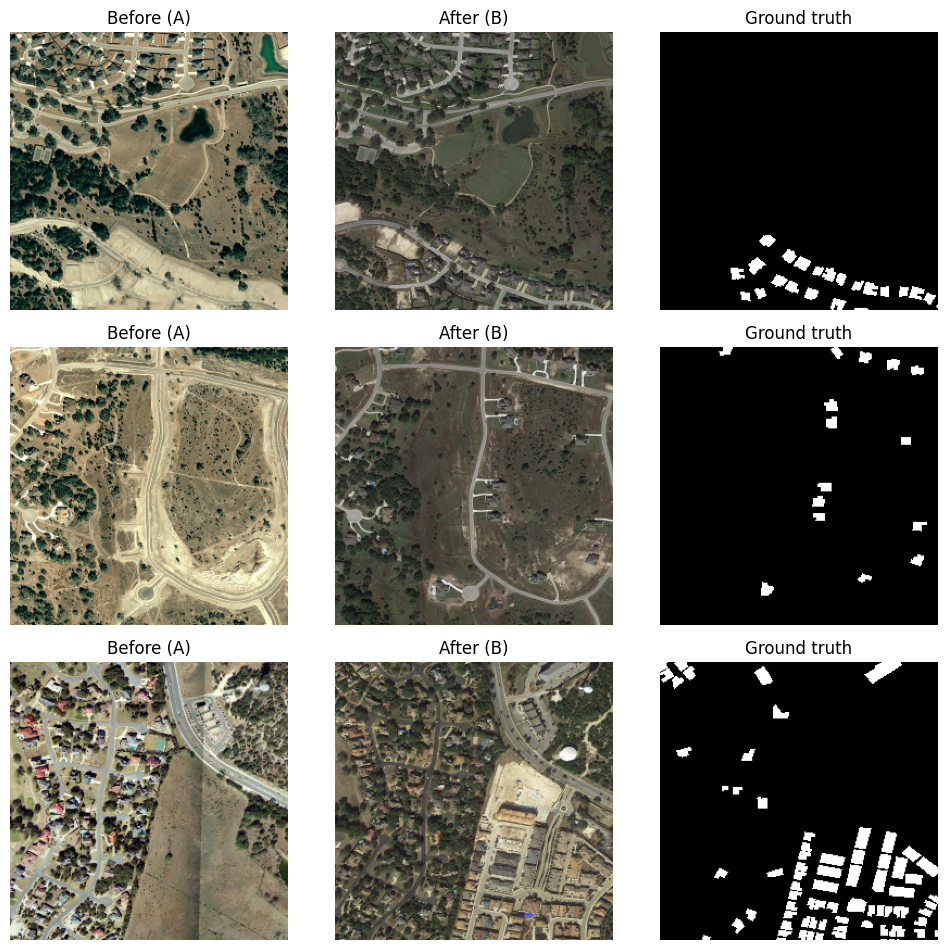

In [ ]:
def show_samples(Xa, Xb, Y, n=3):
    n = min(n, len(Xa))
    fig, axes = plt.subplots(n, 3, figsize=(10, 3.2*n))
    if n == 1:
        axes = np.expand_dims(axes, axis=0)
    for i in range(n):
        axes[i, 0].imshow(Xa[i])
        axes[i, 0].set_title("Before (A)")
        axes[i, 1].imshow(Xb[i])
        axes[i, 1].set_title("After (B)")
        axes[i, 2].imshow(Y[i, ..., 0], cmap="gray", vmin=0, vmax=1)
        axes[i, 2].set_title("Ground truth")
        for ax in axes[i]:
            ax.axis("off")
    plt.tight_layout()
    plt.show()

show_samples(X1_train, X2_train, y_train, n=3)

## 6. Prepare the `tf.data` datasets

Training augmentation is applied in the same way to both dates and the mask. A horizontal flip, vertical flip and rotation by a multiple of 90 degrees are sampled for each pair. The same brightness multiplier is applied to both images so that augmentation does not add an artificial brightness difference between dates.

After augmentation, the ResNet50 preprocessing function is applied to the two RGB images. The validation pipeline does not use augmentation. Both datasets are batched and prefetched for training.


In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

def preprocess_resnet_pair(image_a, image_b):
    # Inputs are RGB float tensors in the original 0..255 scale.
    image_a = tf.keras.applications.resnet50.preprocess_input(
        tf.cast(image_a, tf.float32)
    )
    image_b = tf.keras.applications.resnet50.preprocess_input(
        tf.cast(image_b, tf.float32)
    )
    return (image_a, image_b)

def augment_pair_tf(image_a, image_b, mask):
    # Cast images to float32 to perform brightness modifications safely
    image_a = tf.cast(image_a, tf.float32)
    image_b = tf.cast(image_b, tf.float32)
    mask = tf.cast(mask, tf.float32)

    # Synchronized horizontal and vertical flips.
    do_flip_lr = tf.random.uniform(()) > 0.5
    image_a = tf.cond(do_flip_lr, lambda: tf.image.flip_left_right(image_a), lambda: image_a)
    image_b = tf.cond(do_flip_lr, lambda: tf.image.flip_left_right(image_b), lambda: image_b)
    mask = tf.cond(do_flip_lr, lambda: tf.image.flip_left_right(mask), lambda: mask)

    do_flip_ud = tf.random.uniform(()) > 0.5
    image_a = tf.cond(do_flip_ud, lambda: tf.image.flip_up_down(image_a), lambda: image_a)
    image_b = tf.cond(do_flip_ud, lambda: tf.image.flip_up_down(image_b), lambda: image_b)
    mask = tf.cond(do_flip_ud, lambda: tf.image.flip_up_down(mask), lambda: mask)

    # Synchronized rotation by 0, 90, 180 or 270 degrees.
    k = tf.random.uniform((), minval=0, maxval=4, dtype=tf.int32)
    image_a = tf.image.rot90(image_a, k)
    image_b = tf.image.rot90(image_b, k)
    mask = tf.image.rot90(mask, k)

    # Same brightness multiplier for both dates.
    brightness_factor = tf.random.uniform((), 0.8, 1.2)
    image_a = tf.clip_by_value(image_a * brightness_factor, 0.0, 255.0)
    image_b = tf.clip_by_value(image_b * brightness_factor, 0.0, 255.0)

    return image_a, image_b, mask

def make_dataset(Xa, Xb, Y, training=False):
    ds = tf.data.Dataset.from_tensor_slices((Xa, Xb, Y))
    if training:
        ds = ds.shuffle(
            buffer_size=len(Xa),
            seed=SEED,
            reshuffle_each_iteration=True
        )
        ds = ds.map(augment_pair_tf, num_parallel_calls=AUTOTUNE)

    ds = ds.map(
        lambda a, b, y: (preprocess_resnet_pair(a, b), y),
        num_parallel_calls=AUTOTUNE
    )
    ds = ds.batch(BATCH_SIZE, drop_remainder=False)
    if not training:
        ds = ds.cache()
    return ds.prefetch(AUTOTUNE)

train_ds = make_dataset(X1_train, X2_train, y_train, training=True)
val_ds = make_dataset(X1_val, X2_val, y_val, training=False)

print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())

Training batches: 223
Validation batches: 32


## 7. Build the M5 network

The main encoder is an ImageNet-pretrained ResNet50 with shared weights for the two input dates. The selected feature maps have spatial sizes of 128 × 128, 64 × 64, 32 × 32 and 16 × 16. At each scale, the notebook concatenates the features from both dates with their absolute difference. A 1 × 1 convolution, batch normalization and ReLU project these fused features to 32, 64, 128 and 256 channels, respectively.

The decoder upsamples the fused features from 16 × 16 through 32 × 32, 64 × 64 and 128 × 128. At the final 256 × 256 stage, M5 joins the decoder output with the 16-channel feature map from the additional shallow branch. A 3 × 3 refinement convolution and a one-channel sigmoid output layer produce the final mask.


In [ ]:
@tf.keras.utils.register_keras_serializable()
class AbsoluteDifference(layers.Layer):
    def call(self, inputs):
        return tf.abs(inputs[0] - inputs[1])


def project_temporal_features(feature_a, feature_b, scale_name, output_channels):
    """Existing M2 temporal fusion: A, B and absolute difference, then 1x1 projection."""
    difference = AbsoluteDifference(name=f"{scale_name}_absolute_difference")(
        [feature_a, feature_b]
    )
    combined = layers.Concatenate(name=f"{scale_name}_temporal_concat")(
        [feature_a, feature_b, difference]
    )
    projected = layers.Conv2D(
        output_channels, kernel_size=1, padding="same",
        use_bias=False, name=f"{scale_name}_fusion_projection"
    )(combined)
    projected = layers.BatchNormalization(name=f"{scale_name}_fusion_bn")(projected)
    projected = layers.Activation("relu", name=f"{scale_name}_fusion_relu")(projected)
    return projected


def build_m5_siamese_unet(input_shape=(IMG_SIZE, IMG_SIZE, 3)):
    input_a = layers.Input(shape=input_shape, name="image_before")
    input_b = layers.Input(shape=input_shape, name="image_after")

    # ---------------- Existing M2-256 main Siamese encoder ----------------
    resnet = tf.keras.applications.ResNet50(
        weights="imagenet",
        include_top=False,
        input_shape=input_shape
    )

    feature_layer_names = [
        "conv1_relu",          # 128 x 128 x 64
        "conv2_block3_out",    # 64 x 64 x 256
        "conv3_block4_out",    # 32 x 32 x 512
        "conv4_block6_out"     # 16 x 16 x 1024
    ]

    encoder = tf.keras.Model(
        inputs=resnet.input,
        outputs=[resnet.get_layer(name).output for name in feature_layer_names],
        name="shared_resnet50_encoder"
    )
    encoder.trainable = False

    features_a = encoder(input_a)
    features_b = encoder(input_b)

    projection_channels = [32, 64, 128, 256]
    scale_names = ["scale_128", "scale_64", "scale_32", "scale_16"]

    fused_features = [
        project_temporal_features(fa, fb, name, channels)
        for fa, fb, name, channels in zip(
            features_a, features_b, scale_names, projection_channels
        )
    ]

    # ---------------- Existing M2-256 decoder ----------------
    x = fused_features[3]  # 16 x 16 x 256

    x = layers.UpSampling2D(interpolation="nearest", name="up_to_32")(x)
    x = layers.Concatenate(name="decoder_concat_32")([x, fused_features[2]])
    x = layers.Conv2D(256, 3, padding="same", activation="relu",
                      name="decoder_conv_32")(x)

    x = layers.UpSampling2D(interpolation="nearest", name="up_to_64")(x)
    x = layers.Concatenate(name="decoder_concat_64")([x, fused_features[1]])
    x = layers.Conv2D(128, 3, padding="same", activation="relu",
                      name="decoder_conv_64")(x)

    x = layers.UpSampling2D(interpolation="nearest", name="up_to_128")(x)
    x = layers.Concatenate(name="decoder_concat_128")([x, fused_features[0]])
    x = layers.Conv2D(64, 3, padding="same", activation="relu",
                      name="decoder_conv_128")(x)

    x = layers.UpSampling2D(interpolation="nearest", name="up_to_256")(x)
    # ---------------- NEW M5 full-resolution temporal branch ----------------
    # One lightweight CNN is shared across the before/after images.
    # The branch is kept at 16 channels to control T4 activation memory.
    shallow_input = layers.Input(shape=input_shape, name="shallow_image_input")
    shallow = layers.Conv2D(
        16, 3, padding="same", use_bias=False, name="shallow_conv1"
    )(shallow_input)
    shallow = layers.BatchNormalization(name="shallow_bn1")(shallow)
    shallow = layers.Activation("relu", name="shallow_relu1")(shallow)
    shallow = layers.SeparableConv2D(
        16, 3, padding="same", use_bias=False, name="shallow_separable_conv"
    )(shallow)
    shallow = layers.BatchNormalization(name="shallow_bn2")(shallow)
    shallow = layers.Activation("relu", name="shallow_relu2")(shallow)

    shallow_encoder = models.Model(
        shallow_input, shallow, name="shared_full_resolution_shallow_encoder"
    )
    shallow_a = shallow_encoder(input_a)
    shallow_b = shallow_encoder(input_b)

    shallow_difference = AbsoluteDifference(name="shallow_absolute_difference")(
        [shallow_a, shallow_b]
    )
    shallow_concat = layers.Concatenate(name="shallow_temporal_concat")(
        [shallow_a, shallow_b, shallow_difference]
    )
    shallow_fusion = layers.Conv2D(
        16, 1, padding="same", use_bias=False, name="shallow_fusion_projection"
    )(shallow_concat)
    shallow_fusion = layers.BatchNormalization(name="shallow_fusion_bn")(shallow_fusion)
    shallow_fusion = layers.Activation("relu", name="shallow_fusion_relu")(shallow_fusion)

    # NEW: inject full-resolution temporal features into the final decoder stage.
    x = layers.Concatenate(name="decoder_concat_256_shallow")([x, shallow_fusion])
    x = layers.Conv2D(
        32, 3, padding="same", activation="relu", name="decoder_conv_256_refine"
    )(x)

    output = layers.Conv2D(
        1, 1, activation="sigmoid", dtype="float32",
        name="change_probability"
    )(x)

    model = models.Model(
        [input_a, input_b], output,
        name="M5_HighResolutionSkip_Siamese_UNet"
    )
    return model, encoder, shallow_encoder


model, encoder, shallow_encoder = build_m5_siamese_unet()

# Shape assertions catch spatial mismatch before the expensive training run.
assert model.input_shape[0][1:] == (IMG_SIZE, IMG_SIZE, 3)
assert model.output_shape[1:] == (IMG_SIZE, IMG_SIZE, 1), model.output_shape
assert model.get_layer("shallow_fusion_relu").output.shape[1:3] == (256, 256)
assert model.get_layer("decoder_conv_256_refine").output.shape[1:3] == (256, 256)

print("Verified M5 output shape:", model.output_shape)
print("Verified shallow temporal feature shape:",
      model.get_layer("shallow_fusion_relu").output.shape)
print("M5 includes the unchanged four-scale M2 fusion plus one new full-resolution branch.")
model.summary()


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Verified M5 output shape: (None, 256, 256, 1)
Verified shallow temporal feature shape: (None, 256, 256, 16)
M5 includes the unchanged four-scale M2 fusion plus one new full-resolution branch.


Model: "M5_HighResolutionSkip_Siamese_UNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_before        │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ image_after         │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ shared_resnet50_en… │ [(None, 128, 128, │  8,589,184 │ image_before[0][… │
│ (Functional)        │ 64), (None, 64,   │            │ image_after[0][0] │
│                     │ 64, 256), (None,  │            │                   │
│                     │ 32, 32, 512),     │            │                   │
│                     │ (None, 16, 16,    │            │                   │
│                     │ 1024)]            │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ scale_16_absolute_… │ (None, 16, 16,    │          0 │ shared_resnet50_… │
│ (AbsoluteDifferenc… │ 1024)             │            │ shared_resnet50_… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ scale_16_temporal_… │ (None, 16, 16,    │          0 │ shared_resnet50_… │
│ (Concatenate)       │ 3072)             │            │ shared_resnet50_… │
│                     │                   │            │ scale_16_absolut… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ scale_32_absolute_… │ (None, 32, 32,    │          0 │ shared_resnet50_… │
│ (AbsoluteDifferenc… │ 512)              │            │ shared_resnet50_… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ scale_16_fusion_pr… │ (None, 16, 16,    │    786,432 │ scale_16_tempora… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ scale_32_temporal_… │ (None, 32, 32,    │          0 │ shared_resnet50_… │
│ (Concatenate)       │ 1536)             │            │ shared_resnet50_… │
│                     │                   │            │ scale_32_absolut… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ scale_16_fusion_bn  │ (None, 16, 16,    │      1,024 │ scale_16_fusion_… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ scale_32_fusion_pr… │ (None, 32, 32,    │    196,608 │ scale_32_tempora… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ scale_16_fusion_re… │ (None, 16, 16,    │          0 │ scale_16_fusion_… │
│ (Activation)        │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ scale_32_fusion_bn  │ (None, 32, 32,    │        512 │ scale_32_fusion_… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ scale_64_absolute_… │ (None, 64, 64,    │          0 │ shared_resnet50_… │
│ (AbsoluteDifferenc… │ 256)              │            │ shared_resnet50_… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_to_32            │ (None, 32, 32,    │          0 │ scale_16_fusion_… │
│ (UpSampling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ scale_32_fusion_re… │ (None, 32, 32,    │          0 │ scale_32_fusion_

 Total params: 11,000,321 (41.96 MB)

 Trainable params: 2,410,081 (9.19 MB)

 Non-trainable params: 8,590,240 (32.77 MB)

## 8. Loss function and training metrics

The model is trained with the sum of binary cross-entropy and Dice loss. Dice is calculated for each image in the batch and then averaged across the batch.

Binary accuracy, precision, recall and IoU are also tracked during training. These built-in metrics use a probability threshold of 0.5. The final threshold is selected separately from validation predictions, as described later in the notebook.


In [ ]:
def dice_loss(y_true, y_pred, smooth=1e-6):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)

    axes = [1, 2, 3]
    intersection = tf.reduce_sum(y_true * y_pred, axis=axes)
    denominator = (
        tf.reduce_sum(y_true, axis=axes) +
        tf.reduce_sum(y_pred, axis=axes)
    )
    dice = (2.0 * intersection + smooth) / (denominator + smooth)
    return 1.0 - tf.reduce_mean(dice)

def combined_loss(y_true, y_pred):
    bce = tf.reduce_mean(
        tf.keras.losses.binary_crossentropy(y_true, y_pred)
    )
    return bce + dice_loss(y_true, y_pred)

def compile_model(model, learning_rate):
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss=combined_loss,
        metrics=[
            tf.keras.metrics.BinaryAccuracy(name="binary_accuracy", threshold=0.5),
            tf.keras.metrics.Precision(name="precision", thresholds=0.5),
            tf.keras.metrics.Recall(name="recall", thresholds=0.5),
            tf.keras.metrics.BinaryIoU(
                target_class_ids=[1], threshold=0.5, name="change_iou"
            )
        ]
    )

compile_model(model, learning_rate=1e-4)

## 9. Stage 1: train with the ResNet50 encoder frozen

In the first stage, the pretrained ResNet50 encoder is frozen. The decoder, temporal-fusion projections and M5 shallow branch remain available for training.

The run is configured for up to eight epochs. The best weights are saved according to validation loss. Learning-rate reduction and early stopping are used to limit training when validation loss stops improving.


In [ ]:
import time

class EpochTimer(tf.keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.training_start = time.perf_counter()
        self.epoch_times = []

    def on_epoch_begin(self, epoch, logs=None):
        self.epoch_start = time.perf_counter()

    def on_epoch_end(self, epoch, logs=None):
        elapsed = time.perf_counter() - self.epoch_start
        self.epoch_times.append(elapsed)
        print(f"Epoch {epoch + 1} duration: {elapsed:.1f} sec")

    def on_train_end(self, logs=None):
        total = time.perf_counter() - self.training_start
        print(f"Total fit duration: {total / 60:.2f} min")


In [ ]:
STAGE1_EPOCHS = 8
stage1_weights = "/content/m5_checkpoints_256/m5_stage1_best.weights.h5"

stage1_timer = EpochTimer()
stage1_callbacks = [
    stage1_timer,
    tf.keras.callbacks.ModelCheckpoint(
        stage1_weights,
        monitor="val_loss",
        save_best_only=True,
        save_weights_only=True,
        mode="min",
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True,
        verbose=1
    )
]

history_stage1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=STAGE1_EPOCHS,
    callbacks=stage1_callbacks,
    verbose=1
)

model.load_weights(stage1_weights)
print("Restored best Stage 1 weights.")

Epoch 1/8
223/223 ━━━━━━━━━━━━━━━━━━━━ 0s 207ms/step - binary_accuracy: 0.9426 - change_iou: 0.2063 - loss: 0.9621 - precision: 0.3553 - recall: 0.3239Epoch 1 duration: 123.3 sec

Epoch 1: val_loss improved from None to 0.73016, saving model to /content/m5_checkpoints_256/m5_stage1_best.weights.h5

Epoch 1: finished saving model to /content/m5_checkpoints_256/m5_stage1_best.weights.h5
223/223 ━━━━━━━━━━━━━━━━━━━━ 124s 268ms/step - binary_accuracy: 0.9490 - change_iou: 0.2896 - loss: 0.8571 - precision: 0.4453 - recall: 0.4530 - val_binary_accuracy: 0.9692 - val_change_iou: 0.4299 - val_loss: 0.7302 - val_precision: 0.6593 - val_recall: 0.5526 - learning_rate: 1.0000e-04
Epoch 2/8
221/223 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - binary_accuracy: 0.9623 - change_iou: 0.4018 - loss: 0.7242 - precision: 0.5688 - recall: 0.5790Epoch 2 duration: 5.6 sec

Epoch 2: val_loss improved from 0.73016 to 0.70195, saving model to /content/m5_checkpoints_256/m5_stage1_best.weights.h5

Epoch 2: finished sav

## 10. Stage 2: fine-tune the final ResNet50 stage

For the second stage, the convolutional layers in ResNet50's `conv4_` stage are made trainable. Batch-normalization layers and the earlier encoder stages remain frozen. The model is recompiled with a lower learning rate of `1e-5` before fine-tuning.

This stage is configured for up to 40 epochs. The best checkpoint is selected using validation loss, with learning-rate reduction and early stopping enabled.


In [ ]:
# Unfreeze only convolutional layers in the ResNet conv4 stage.
encoder.trainable = True
for layer in encoder.layers:
    if layer.name.startswith("conv4_") and not isinstance(
        layer, tf.keras.layers.BatchNormalization
    ):
        layer.trainable = True
    else:
        layer.trainable = False

trainable_encoder_layers = [
    layer.name for layer in encoder.layers if layer.trainable
]
print("Trainable encoder layers:", len(trainable_encoder_layers))
print(trainable_encoder_layers[:10])

# Recompile after changing trainable flags.
compile_model(model, learning_rate=1e-5)

STAGE2_EPOCHS = 40
stage2_weights = "/content/m5_checkpoints_256/m5_stage2_best.weights.h5"

stage2_timer = EpochTimer()
stage2_callbacks = [
    stage2_timer,
    tf.keras.callbacks.ModelCheckpoint(
        stage2_weights,
        monitor="val_loss",
        save_best_only=True,
        save_weights_only=True,
        mode="min",
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True,
        verbose=1
    )
]

history_stage2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=STAGE2_EPOCHS,
    callbacks=stage2_callbacks,
    verbose=1
)

model.load_weights(stage2_weights)
print("Restored best Stage 2 weights.")

Trainable encoder layers: 43
['conv4_block1_1_conv', 'conv4_block1_1_relu', 'conv4_block1_2_conv', 'conv4_block1_2_relu', 'conv4_block1_0_conv', 'conv4_block1_3_conv', 'conv4_block1_add', 'conv4_block1_out', 'conv4_block2_1_conv', 'conv4_block2_1_relu']
Epoch 1/40
223/223 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step - binary_accuracy: 0.9765 - change_iou: 0.5597 - loss: 0.5407 - precision: 0.7391 - recall: 0.6966Epoch 1 duration: 84.9 sec

Epoch 1: val_loss improved from None to 0.56993, saving model to /content/m5_checkpoints_256/m5_stage2_best.weights.h5

Epoch 1: finished saving model to /content/m5_checkpoints_256/m5_stage2_best.weights.h5
223/223 ━━━━━━━━━━━━━━━━━━━━ 86s 183ms/step - binary_accuracy: 0.9754 - change_iou: 0.5690 - loss: 0.5222 - precision: 0.7436 - recall: 0.7079 - val_binary_accuracy: 0.9787 - val_change_iou: 0.5896 - val_loss: 0.5699 - val_precision: 0.7543 - val_recall: 0.7298 - learning_rate: 1.0000e-05
Epoch 2/40
222/223 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - binary_accura

## 11. Choose between the two training stages

After both stages finish, each saved checkpoint is evaluated on the validation set. The notebook keeps the checkpoint with the lower validation loss and saves it as the final M5 model.

The test set is not used for this selection. It is loaded only after the model checkpoint and the probability threshold have been fixed.


In [ ]:
# Evaluate Stage 2 checkpoint.
model.load_weights(stage2_weights)
stage2_val_loss = float(model.evaluate(val_ds, verbose=0)[0])

# Evaluate Stage 1 checkpoint.
model.load_weights(stage1_weights)
stage1_val_loss = float(model.evaluate(val_ds, verbose=0)[0])

if stage2_val_loss <= stage1_val_loss:
    model.load_weights(stage2_weights)
    selected_stage = "Stage 2 (fine-tuned encoder)"
    selected_val_loss = stage2_val_loss
else:
    model.load_weights(stage1_weights)
    selected_stage = "Stage 1 (frozen encoder)"
    selected_val_loss = stage1_val_loss

print("Stage 1 validation loss:", stage1_val_loss)
print("Stage 2 validation loss:", stage2_val_loss)
print("Selected checkpoint:", selected_stage)
print("Selected validation loss:", selected_val_loss)

FINAL_MODEL_PATH = "/content/m5_checkpoints_256/M5_HighResolutionSkip_Siamese_UNet_256.keras"
model.save(FINAL_MODEL_PATH)
print("Saved model:", FINAL_MODEL_PATH)

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'loss_scale_optimizer', because it has 146 variables whereas the saved optimizer has 70 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 142 variables whereas the saved optimizer has 66 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Stage 1 validation loss: 0.5928441286087036
Stage 2 validation loss: 0.5481130480766296
Selected checkpoint: Stage 2 (fine-tuned encoder)
Selected validation loss: 0.5481130480766296
Saved model: /content/m5_checkpoints_256/M5_HighResolutionSkip_Siamese_UNet_256.keras


## 12. Review the training history

The next plot shows training and validation loss for the frozen-encoder and fine-tuning stages. The curves provide a quick check of how the model fitted the training data and whether validation loss continued to improve.


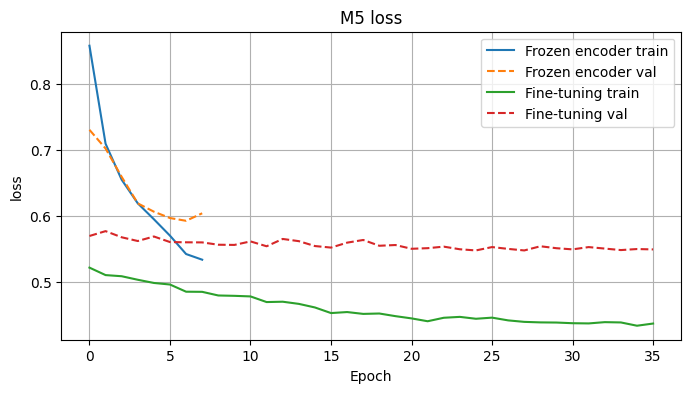

In [ ]:
def plot_histories(*histories, labels=None, metric="loss"):
    plt.figure(figsize=(8, 4))
    for i, hist in enumerate(histories):
        label = labels[i] if labels else f"Stage {i+1}"
        if metric in hist.history:
            plt.plot(hist.history[metric], label=f"{label} train")
        val_key = "val_" + metric
        if val_key in hist.history:
            plt.plot(hist.history[val_key], linestyle="--", label=f"{label} val")
    plt.xlabel("Epoch")
    plt.ylabel(metric)
    plt.title(f"M5 {metric}")
    plt.legend()
    plt.grid(True)
    plt.show()

plot_histories(history_stage1, history_stage2,
               labels=["Frozen encoder", "Fine-tuning"], metric="loss")

## 13. Select the probability threshold on the validation set

The model first predicts probabilities for the validation images. The notebook evaluates thresholds from 0.05 to 0.95 in steps of 0.05 and selects the threshold with the highest global pixel-level F1-score.

For each threshold, the pixel counts are accumulated over the validation set before precision, recall, F1 and IoU are calculated. The selected threshold is stored in `BEST_THRESHOLD` and is kept fixed for the final test evaluation and the interactive prediction cell. Test labels are not used to choose it.


In [ ]:
def predict_dataset(model, dataset):
    return model.predict(dataset, verbose=1)

val_probs = predict_dataset(model, val_ds)

def binary_metrics(y_true, y_prob, threshold=0.5):
    y_true = np.asarray(y_true).astype(np.uint8).reshape(-1)
    y_pred = (np.asarray(y_prob).reshape(-1) >= threshold).astype(np.uint8)

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    accuracy = (tp + tn) / max(tp + tn + fp + fn, 1)
    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    f1 = 2 * precision * recall / max(precision + recall, 1e-12)
    iou = tp / max(tp + fp + fn, 1)
    dice = 2 * tp / max(2 * tp + fp + fn, 1)

    return {
        "threshold": float(threshold),
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "iou": iou,
        "dice": dice,
        "tp": int(tp), "fp": int(fp), "fn": int(fn), "tn": int(tn)
    }

thresholds = np.arange(0.05, 0.96, 0.05)
val_rows = [
    binary_metrics(y_val, val_probs, threshold=t)
    for t in thresholds
]
val_threshold_table = pd.DataFrame(val_rows)
display(val_threshold_table)

best_idx = val_threshold_table["f1"].idxmax()
BEST_THRESHOLD = float(val_threshold_table.loc[best_idx, "threshold"])
print("Selected validation threshold:", BEST_THRESHOLD)
print("Validation metrics at selected threshold:")
display(pd.DataFrame([val_rows[best_idx]]))

32/32 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step


,threshold,accuracy,precision,recall,f1,iou,dice,tp,fp,fn,tn
0,0.05,0.969819,0.594641,0.882037,0.710372,0.550835,0.710372,155243,105827,20762,3912472
1,0.10,0.973495,0.636655,0.858089,0.730970,0.576007,0.730970,151028,86193,24977,3932106
2,0.15,0.975291,0.661718,0.841192,0.740739,0.588232,0.740739,148054,75688,27951,3942611
3,0.20,0.976471,0.680631,0.827658,0.746978,0.596142,0.746978,145672,68353,30333,3949946
4,0.25,0.977346,0.696495,0.815494,0.751312,0.601681,0.751312,143531,62545,32474,3955754
5,0.30,0.978028,0.710379,0.804295,0.754425,0.605685,0.754425,141560,57714,34445,3960585
6,0.35,0.978507,0.722103,0.792995,0.755890,0.607575,0.755890,139571,53713,36434,3964586
7,0.40,0.978916,0.733056,0.782523,0.756982,0.608987,0.756982,137728,50154,38277,3968145
8,0.45,0.979293,0.743734,0.772819,0.757998,0.610303,0.757998,136020,46868,39985,3971431
9,0.50,0.979577,0.754094,0.761677,0.757866,0.610133,0.757866,134059,43716,41946,3974583


Selected validation threshold: 0.45
Validation metrics at selected threshold:


,threshold,accuracy,precision,recall,f1,iou,dice,tp,fp,fn,tn
0,0.45,0.979293,0.743734,0.772819,0.757998,0.610303,0.757998,136020,46868,39985,3971431


## 14. Evaluate the held-out test set

With the checkpoint and threshold selected, the notebook loads the 128 test pairs and predicts their change probabilities. It then calculates accuracy, precision, recall, F1-score, IoU and Dice using the fixed validation threshold.

These are the final test results for this M5 run. The threshold should not be adjusted after viewing the test metrics.


In [ ]:
X1_test, X2_test, y_test = load_split(test_pairs, "test")
test_ds = make_dataset(X1_test, X2_test, y_test, training=False)

test_probs = predict_dataset(model, test_ds)
test_results = binary_metrics(y_test, test_probs, threshold=BEST_THRESHOLD)

print("M5 FINAL TEST RESULTS")
display(pd.DataFrame([test_results]))

test: A=(128, 256, 256, 3), B=(128, 256, 256, 3), mask=(128, 256, 256, 1), mask values=[0. 1.]
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step
M5 FINAL TEST RESULTS


,threshold,accuracy,precision,recall,f1,iou,dice,tp,fp,fn,tn
0,0.45,0.974086,0.734694,0.768812,0.751366,0.60175,0.751366,328461,118611,98771,7842765


## 15. View predictions on test samples

The next figure shows four test examples. For each pair, it displays the before image, after image, ground-truth mask, predicted mask and prediction overlay on the after image. These examples help illustrate where the model detects changes and where it misses or incorrectly labels pixels.


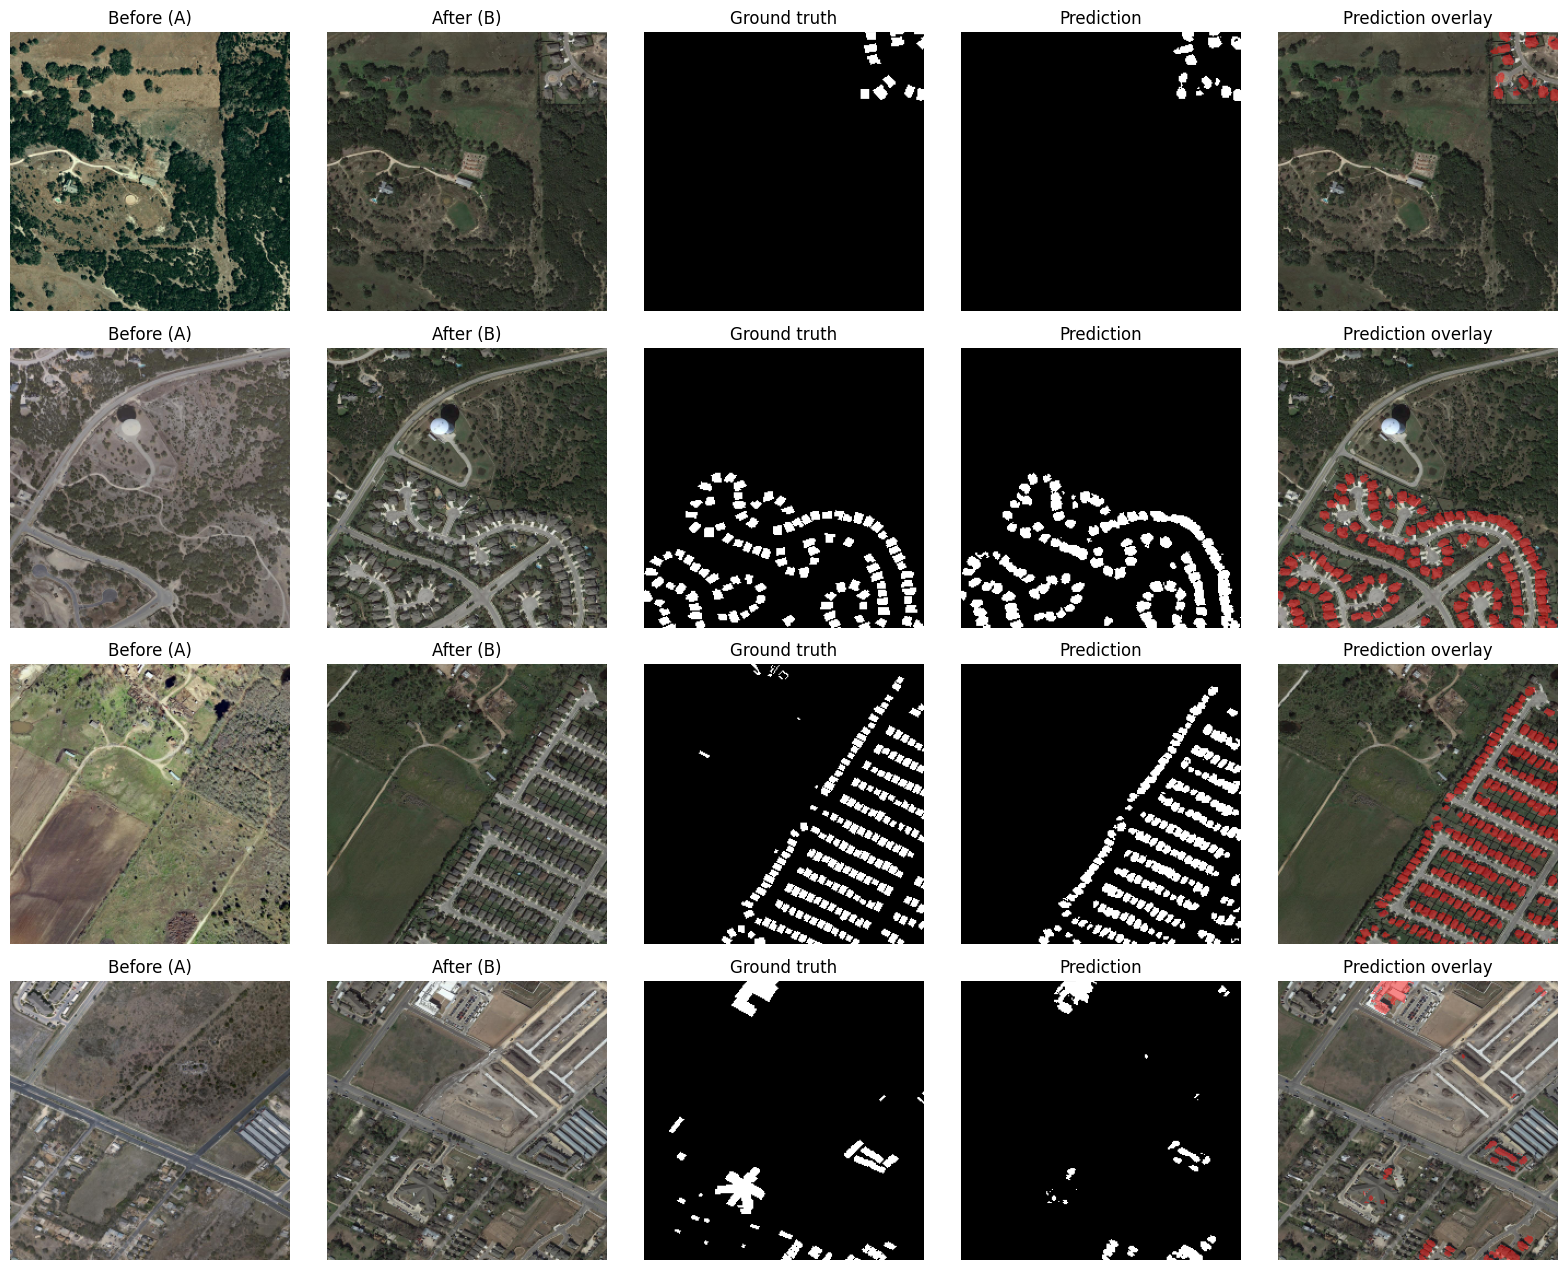

In [ ]:
def visualize_predictions(Xa, Xb, Y, probabilities, threshold, indices=None, n=4):
    if indices is None:
        indices = list(range(min(n, len(Xa))))
    fig, axes = plt.subplots(len(indices), 5, figsize=(16, 3.2*len(indices)))
    if len(indices) == 1:
        axes = np.expand_dims(axes, axis=0)

    for row, idx in enumerate(indices):
        pred = (probabilities[idx, ..., 0] >= threshold).astype(np.uint8)
        gt = Y[idx, ..., 0]

        overlay = Xb[idx].copy()
        changed = pred == 1
        # Highlight predicted changes in red.
        overlay[changed] = (
            0.55 * overlay[changed] + 0.45 * np.array([255, 0, 0])
        ).astype(np.uint8)

        panels = [
            (Xa[idx], "Before (A)", None),
            (Xb[idx], "After (B)", None),
            (gt, "Ground truth", "gray"),
            (pred, "Prediction", "gray"),
            (overlay, "Prediction overlay", None)
        ]
        for col, (image, title, cmap) in enumerate(panels):
            axes[row, col].imshow(image, cmap=cmap, vmin=0, vmax=1 if cmap else None)
            axes[row, col].set_title(title)
            axes[row, col].axis("off")

    plt.tight_layout()
    plt.show()

visualize_predictions(
    X1_test, X2_test, y_test, test_probs,
    BEST_THRESHOLD, indices=[0, 1, 2, 3]
)

## 16. Save the model and evaluation files

The final M5 model, test metrics and validation-threshold table are copied to the `LEVIR-CD_M5_outputs` folder in Google Drive. Keeping these files together makes it easier to load the trained model for inference and to refer back to the threshold and results for this run.


In [ ]:
import shutil

DRIVE_OUTPUT = "/content/drive/MyDrive/LEVIR-CD_M5_outputs"
os.makedirs(DRIVE_OUTPUT, exist_ok=True)

shutil.copy2(FINAL_MODEL_PATH, os.path.join(DRIVE_OUTPUT, "M5_HighResolutionSkip_Siamese_UNet_256.keras"))
pd.DataFrame([test_results]).to_csv(
    os.path.join(DRIVE_OUTPUT, "M5_test_metrics.csv"), index=False
)
val_threshold_table.to_csv(
    os.path.join(DRIVE_OUTPUT, "M5_validation_thresholds.csv"), index=False
)

print("Saved M5 model and results to:", DRIVE_OUTPUT)

Saved M5 model and results to: /content/drive/MyDrive/LEVIR-CD_M5_outputs


## 17. Summary of the M5 run

M5 uses the 445 training, 64 validation and 128 test pairs in the project split. Each complete image and label is resized to 256 × 256. The notebook checks the filename stems before pairing the two dates and their labels.

The main pathway uses an ImageNet-pretrained shared ResNet50 encoder and the four-scale temporal fusion from M2-256. The added M5 branch applies a shared shallow CNN to both images, combines the two feature maps with their absolute difference, and projects the result to 16 channels. This feature map is joined to the decoder at 256 × 256 before the final refinement convolution.

Training uses BCE + Dice loss and Adam. The ResNet50 encoder is frozen in Stage 1; the convolutional layers in `conv4_` are fine-tuned in Stage 2 while batch-normalization layers remain frozen. The selected checkpoint and probability threshold are both chosen using validation data. The random seed for this run is 44.


## 18. Comparison with the M2-256 run

The table compares the M2-256 seed-43 result with the M5 result saved in this notebook. Both runs use a threshold of 0.45.

| Model | Seed | Threshold | Test F1 | Test IoU |
|---|---:|---:|---:|---:|
| M2-256 | 43 | 0.45 | 74.3472% | 59.1688% |
| M5 (this notebook) | 44 | 0.45 | 75.1366% | 60.1750% |

For these runs, M5 is higher by 0.7894 percentage points in F1 and 1.0062 percentage points in IoU. The runs use different random seeds, so this result should be treated as an observed difference between two runs, not as proof that the added branch will improve performance consistently. The principal M2-256 seed-42 result at threshold 0.55 is a separate evaluation and is not the same-threshold comparison shown here.

The M5 test values stored in this notebook differ from the M5 values in the previously prepared project report. Before submitting both files, make sure the report identifies the same run as the notebook, or clearly labels the results as separate runs.


## 19. Predict changes in an uploaded image pair

This section can be used after the model and `BEST_THRESHOLD` have been created by the earlier cells. Upload the **before image (A)** and **after image (B)** in separate prompts. The notebook resizes both images to 256 × 256, converts them to RGB and applies the same ResNet50 preprocessing used during training. It then displays the probability map and binary prediction, and saves the predicted mask as a PNG file.

The two images must show the same geographical area and should be spatially aligned. The code resizes each image directly to 256 × 256, so use matching image dimensions; non-square images will be stretched to a square input.

A ground-truth mask can be uploaded afterward. It is resized with nearest-neighbour interpolation and converted to a binary mask, with zero treated as unchanged and non-zero treated as changed. When a mask is supplied, the notebook reports pixel-level precision, recall, F1/Dice, IoU and accuracy, and displays a colour-coded comparison: green for true positives, red for false positives and blue for false negatives.

The metrics in this section describe only the uploaded image pair. They are not the aggregate test-set results reported above. If no ground-truth mask is supplied, the prediction is still displayed and the comparison metrics are skipped.


STEP 1/2: Upload the BEFORE image (Image A). Select only one file.


Saving train_642_A.png to train_642_A (2).png
\nSTEP 2/2: Upload the AFTER image (Image B). Select only one file.


Saving train_642_B.png to train_642_B (2).png
Input A: train_642_A (2).png
Input B: train_642_B (2).png
Model input/output size: 256×256
Prediction threshold (selected on validation data): 0.45


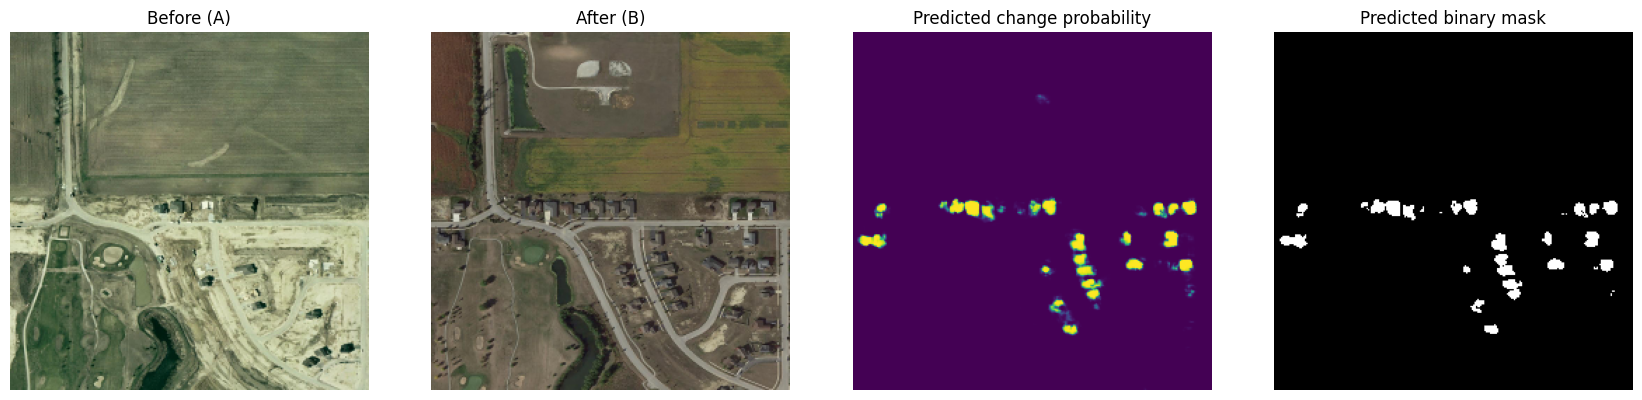

Predicted mask saved to: /content/M5_uploaded_pair_prediction.png

Optional: upload the ground-truth change mask for this same image pair.
The mask should mark changed pixels as non-zero (usually white) and unchanged pixels as zero (black).


Saving train_642_L.png to train_642_L (1).png
Ground-truth mask: train_642_L (1).png


,Threshold,Precision,Recall,IoU,Dice / F1,Pixel accuracy,TP,FP,FN,TN
0,0.45,0.7371,0.6605,0.5346,0.6967,0.9848,1144,408,588,63396


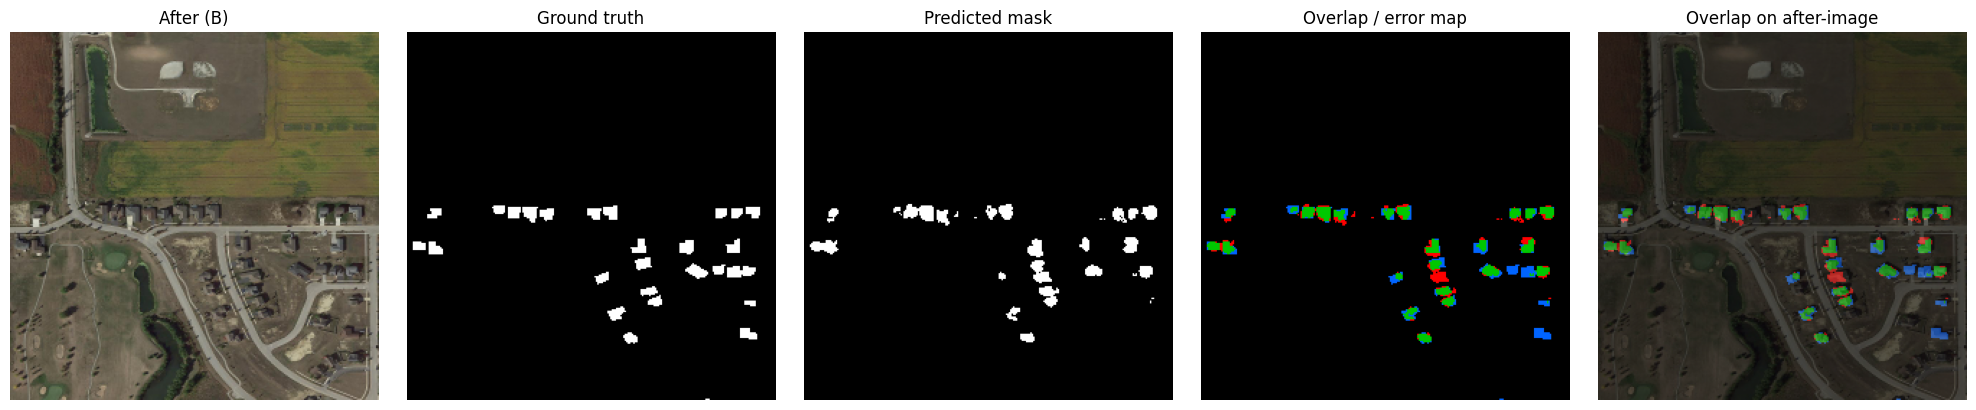

Overlap map legend: GREEN = TP (correct change), RED = FP (false alarm), BLUE = FN (missed change), BLACK = TN.
IoU: 0.5346 | Dice/F1: 0.6967
Saved: /content/M5_uploaded_ground_truth.png
Saved: /content/M5_uploaded_overlap_map.png


In [ ]:
# ========================= SECTION 1: UPLOAD TWO IMAGES AND PREDICT =========================
from google.colab import files
from IPython.display import display
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

def decode_uploaded_image(uploaded_bytes, filename, grayscale=False):
    """Decode an uploaded image without requiring it to be saved manually."""
    flag = cv2.IMREAD_GRAYSCALE if grayscale else cv2.IMREAD_COLOR
    array = np.frombuffer(uploaded_bytes, dtype=np.uint8)
    image = cv2.imdecode(array, flag)
    if image is None:
        raise ValueError(f"Could not decode '{filename}'. Please upload a valid image.")
    if not grayscale:
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    return image

# Upload image A and image B in separate prompts so their order is unambiguous.
print("STEP 1/2: Upload the BEFORE image (Image A). Select only one file.")
uploaded_a = files.upload()

if len(uploaded_a) != 1:
    raise ValueError(f"Please upload exactly one BEFORE image (A). Received {len(uploaded_a)} files.")

uploaded_a_name = next(iter(uploaded_a))
uploaded_a_original = decode_uploaded_image(
    uploaded_a[uploaded_a_name], uploaded_a_name
)

print("\\nSTEP 2/2: Upload the AFTER image (Image B). Select only one file.")
uploaded_b = files.upload()

if len(uploaded_b) != 1:
    raise ValueError(f"Please upload exactly one AFTER image (B). Received {len(uploaded_b)} files.")

uploaded_b_name = next(iter(uploaded_b))
uploaded_b_original = decode_uploaded_image(
    uploaded_b[uploaded_b_name], uploaded_b_name
)

image_a = cv2.resize(
    uploaded_a_original, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA
).astype(np.uint8)
image_b = cv2.resize(
    uploaded_b_original, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA
).astype(np.uint8)

# Apply the exact ResNet50 preprocessing convention used by the training pipeline.
image_a_input = tf.keras.applications.resnet50.preprocess_input(
    image_a.astype(np.float32)
)
image_b_input = tf.keras.applications.resnet50.preprocess_input(
    image_b.astype(np.float32)
)

# Use the validation-selected threshold; do not adjust it using the ground truth.
inference_threshold = float(BEST_THRESHOLD)
prediction_probability = model.predict(
    [image_a_input[np.newaxis, ...], image_b_input[np.newaxis, ...]],
    verbose=0
)[0, ..., 0]

predicted_mask = (prediction_probability >= inference_threshold).astype(np.uint8)

print(f"Input A: {uploaded_a_name}")
print(f"Input B: {uploaded_b_name}")
print(f"Model input/output size: {IMG_SIZE}×{IMG_SIZE}")
print(f"Prediction threshold (selected on validation data): {inference_threshold:.2f}")

fig, axes = plt.subplots(1, 4, figsize=(17, 4))
axes[0].imshow(image_a)
axes[0].set_title("Before (A)")
axes[1].imshow(image_b)
axes[1].set_title("After (B)")
axes[2].imshow(prediction_probability, cmap="viridis", vmin=0, vmax=1)
axes[2].set_title("Predicted change probability")
axes[3].imshow(predicted_mask, cmap="gray", vmin=0, vmax=1)
axes[3].set_title("Predicted binary mask")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

# Optional: download the predicted mask as a PNG file.
predicted_mask_png = (predicted_mask * 255).astype(np.uint8)
prediction_output_path = "/content/M5_uploaded_pair_prediction.png"
cv2.imwrite(prediction_output_path, predicted_mask_png)
print("Predicted mask saved to:", prediction_output_path)


# ========================= SECTION 2: UPLOAD GROUND TRUTH AND COMPARE =========================
print("\nOptional: upload the ground-truth change mask for this same image pair.")
print("The mask should mark changed pixels as non-zero (usually white) and unchanged pixels as zero (black).")
uploaded_gt = files.upload()

if len(uploaded_gt) == 0:
    print("No ground-truth mask uploaded. Prediction is displayed above; overlap metrics were skipped.")
elif len(uploaded_gt) > 1:
    raise ValueError("Please upload only one ground-truth mask.")
else:
    gt_name = next(iter(uploaded_gt))
    gt_original = decode_uploaded_image(
        uploaded_gt[gt_name], gt_name, grayscale=True
    )
    gt_resized = cv2.resize(
        gt_original, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST
    )
    ground_truth_mask = (gt_resized > 0).astype(np.uint8)

    # Pixel-level confusion counts and overlap metrics.
    tp = int(np.logical_and(predicted_mask == 1, ground_truth_mask == 1).sum())
    fp = int(np.logical_and(predicted_mask == 1, ground_truth_mask == 0).sum())
    fn = int(np.logical_and(predicted_mask == 0, ground_truth_mask == 1).sum())
    tn = int(np.logical_and(predicted_mask == 0, ground_truth_mask == 0).sum())

    epsilon = 1e-7
    precision = tp / (tp + fp + epsilon)
    recall = tp / (tp + fn + epsilon)
    iou = tp / (tp + fp + fn + epsilon)
    dice = (2 * tp) / (2 * tp + fp + fn + epsilon)
    pixel_accuracy = (tp + tn) / (tp + tn + fp + fn + epsilon)

    overlap_metrics = pd.DataFrame([{
        "Threshold": inference_threshold,
        "Precision": precision,
        "Recall": recall,
        "IoU": iou,
        "Dice / F1": dice,
        "Pixel accuracy": pixel_accuracy,
        "TP": tp, "FP": fp, "FN": fn, "TN": tn
    }])
    print(f"Ground-truth mask: {gt_name}")
    display(overlap_metrics.style.format({
        "Threshold": "{:.2f}", "Precision": "{:.4f}", "Recall": "{:.4f}",
        "IoU": "{:.4f}", "Dice / F1": "{:.4f}", "Pixel accuracy": "{:.4f}"
    }))

    # Overlay convention: green = true positive, red = false positive,
    # blue = false negative. Black = true negative/background.
    comparison_overlay = np.zeros((IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)
    comparison_overlay[
        (predicted_mask == 1) & (ground_truth_mask == 1)
    ] = [0, 200, 0]       # Correctly detected change (TP)
    comparison_overlay[
        (predicted_mask == 1) & (ground_truth_mask == 0)
    ] = [255, 0, 0]       # False alarm (FP)
    comparison_overlay[
        (predicted_mask == 0) & (ground_truth_mask == 1)
    ] = [0, 100, 255]     # Missed change (FN)

    fig, axes = plt.subplots(1, 5, figsize=(20, 4))
    axes[0].imshow(image_b)
    axes[0].set_title("After (B)")
    axes[1].imshow(ground_truth_mask, cmap="gray", vmin=0, vmax=1)
    axes[1].set_title("Ground truth")
    axes[2].imshow(predicted_mask, cmap="gray", vmin=0, vmax=1)
    axes[2].set_title("Predicted mask")
    axes[3].imshow(comparison_overlay)
    axes[3].set_title("Overlap / error map")
    axes[4].imshow(image_b)
    axes[4].imshow(comparison_overlay, alpha=0.55)
    axes[4].set_title("Overlap on after-image")
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

    print("Overlap map legend: GREEN = TP (correct change), RED = FP (false alarm), BLUE = FN (missed change), BLACK = TN.")
    print(f"IoU: {iou:.4f} | Dice/F1: {dice:.4f}")

    # Save the ground truth and color-coded comparison for later inspection.
    cv2.imwrite("/content/M5_uploaded_ground_truth.png", ground_truth_mask * 255)
    cv2.imwrite(
        "/content/M5_uploaded_overlap_map.png",
        cv2.cvtColor(comparison_overlay, cv2.COLOR_RGB2BGR)
    )
    print("Saved: /content/M5_uploaded_ground_truth.png")
    print("Saved: /content/M5_uploaded_overlap_map.png")
